In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
np.random.seed(42)

n = 100

study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)

final_score = (
    (0.5 * study_hours) +
    (0.3 * attendance) +
    (0.2 * previous_mark) +
    np.random.normal(0, 5, n)
)

df = pd.DataFrame({
    'study_hours': study_hours,
    'attendance': attendance,
    'previous_mark': previous_mark,
    'final_score': final_score
})


# Add dirty records
df.loc[0:5, 'study_hours'] = np.nan
df.loc[99, 'study_hours'] = 50
df.loc[98, 'attendance'] = -10


df

,study_hours,attendance,previous_mark,final_score
0,NaN,70.846293,75.366810,35.178989
1,NaN,80.793547,78.411768,39.481248
2,NaN,81.572855,86.245769,48.605167
3,NaN,76.977227,85.807031,47.329456
4,NaN,83.387143,49.334959,37.044473
...,...,...,...,...
95,2.072970,88.853174,59.606356,37.267830
96,5.592241,76.161426,83.493998,33.777675
97,5.522111,86.537251,74.609493,50.413491
98,5.010227,-10.000000,82.192932,44.045627


In [3]:
df.isnull().sum()

study_hours      6
attendance       0
previous_mark    0
final_score      0
dtype: int64

In [4]:
df['study_hours'] = df['study_hours'].fillna(
    df['study_hours'].median()
)

df.isnull().sum()

study_hours      0
attendance       0
previous_mark    0
final_score      0
dtype: int64

In [5]:
df[df['study_hours'] > 20]

,study_hours,attendance,previous_mark,final_score
99,50.0,73.570297,79.444433,46.41447


In [6]:
df = df[df['study_hours'] < 20]

df.shape

(99, 4)

## Part A — Inspect and Clean

The outlier in study_hours was the student with 50 hours.

This value was removed because it is unrealistic compared to the normal study hours range and could affect the analysis.

Feature matrix:
- study_hours
- attendance
- previous_mark

Target variable:
- final_score

In [8]:
print("Mean:")
print(df.mean())

print("\nMedian:")
print(df.median())

print("\nStandard Deviation:")
print(df.std())

Mean:
study_hours       4.741941
attendance       84.375275
previous_mark    70.887878
final_score      42.654355
dtype: float64

Median:
study_hours       4.812342
attendance       85.996514
previous_mark    71.228112
final_score      42.673003
dtype: float64

Standard Deviation:
study_hours       1.783892
attendance       13.501420
previous_mark    16.324375
final_score       6.106089
dtype: float64


## Observations

1. Study hours are generally consistent among students.

2. Attendance shows some variation between students.

3. Final scores differ between students, showing other factors affect performance.

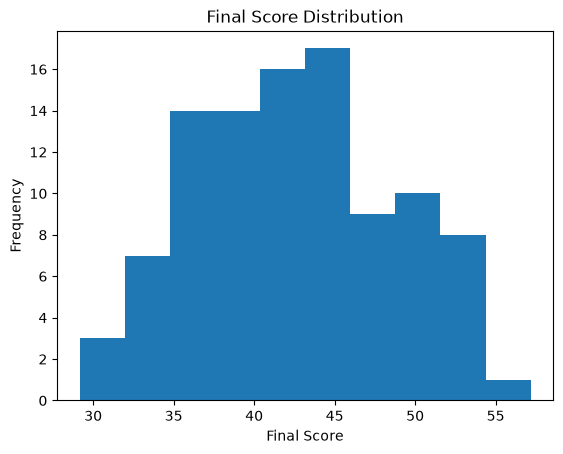

In [9]:
plt.hist(df['final_score'])

plt.xlabel("Final Score")
plt.ylabel("Frequency")
plt.title("Final Score Distribution")

plt.show()

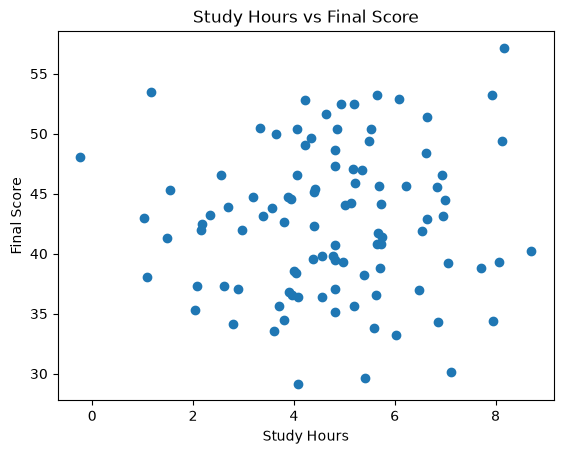

In [10]:
plt.scatter(df['study_hours'], df['final_score'])

plt.xlabel("Study Hours")
plt.ylabel("Final Score")
plt.title("Study Hours vs Final Score")

plt.show()

The scatter plot shows a positive trend, meaning higher study hours may slightly increase final scores.

In [11]:
correlation = df['study_hours'].corr(df['final_score'])

correlation

np.float64(0.04956992716567295)

The Pearson correlation is very weak positive.

Correlation does not guarantee a specific score.
Other factors like attendance, motivation, previous knowledge, and study quality can affect results.

In [12]:
x = df[['study_hours','attendance','previous_mark']].iloc[0].values

w = np.array([0.5,0.2,0.4])

b = 5

y = np.dot(w,x)+b

print(y)

51.72215347600458


The weight vector represents the importance of each feature in prediction.

The bias allows the prediction value to shift and improves flexibility.

In [13]:
df['study_hours_scaled'] = (
    df['study_hours'] - df['study_hours'].mean()
) / df['study_hours'].std()


df['previous_mark_scaled'] = (
    df['previous_mark'] - df['previous_mark'].mean()
) / df['previous_mark'].std()


df.head()

,study_hours,attendance,previous_mark,final_score,study_hours_scaled,previous_mark_scaled
0,4.812342,70.846293,75.366810,35.178989,0.039465,0.274371
1,4.812342,80.793547,78.411768,39.481248,0.039465,0.460899
2,4.812342,81.572855,86.245769,48.605167,0.039465,0.940795
3,4.812342,76.977227,85.807031,47.329456,0.039465,0.913919
4,4.812342,83.387143,49.334959,37.044473,0.039465,-1.320291


Without scaling, KNN would be affected because previous_mark values are much larger than study_hours values.
The larger feature would dominate distance calculations.